# 最低賃金の発効時期とパート求人：基礎案（実行済み）
課題3：モデル・方法、課題4：実データでの仮説検証。2026年11月4日版。

このnotebookはリポジトリのローカルデータを読み、`analysis.py`の全検算を実行する。原データ・過去の発表は変更しない。未公開のColabリンクは使わない。

## 実行方法
リポジトリ内で `python 2026-11-04/01-basic/build_materials.py` を実行するか、このフォルダを作業ディレクトリとしてセルを上から実行する。依存関係は `requirements.txt`。先に `analysis.py` を実行すればフォントを含む図も作れる。企業パラメータは推定しない。


In [1]:
from pathlib import Path
import sys
HERE = Path.cwd()
if not (HERE / 'analysis.py').is_file():
    HERE = HERE / '2026-11-04' / '01-basic'
assert (HERE / 'analysis.py').is_file(), 'リポジトリのルートか本フォルダから実行してください'
sys.path.insert(0, str(HERE))
import analysis
import pandas as pd
from IPython.display import display, Image
result = analysis.run()


   baseline  pre_gap  nov_gap     delta    ci_low  ci_high  p_one_sided_negative  p_two_sided
2025-01..09 1.621819 0.066409 -1.555410 -7.933878 4.823057              0.310082     0.620164
2025-01..07 2.246230 0.066409 -2.179821 -8.847660 4.488018              0.253191     0.506381
2025-04..09 1.114989 0.066409 -1.048580 -7.314093 5.216933              0.366780     0.733559
PASS: six-sheet data checks; year headers; 47 prefectures; unchanged raw hashes; Welch/OLS; model grid.


## 1. 観測する変数と比較
新規求人数はハローワークが新しく受け付けた採用予定人員であり、広告件数・有効求人ストック・実際の採用人数ではない。一般パート（第12表-3）、受理地の統計を使う。11月発効13県を除き、10月発効20県と12月以降14県を比較する。各県等重み。

年度見出しを検索して令和6・7年度を選び、令和8年度列を誤って使わない。六つのシートで全月連続・全国合計を検査し、一般・常用のそれぞれで `part + nonpart = total` を検算した。原データのSHA-256も実行前後で一致する。


In [2]:
v = result['validation']
display({k:v[k] for k in ['raw_first_month','raw_last_month','raw_months','prefectures','panel_observations','group_counts','workbook_year_headers','raw_files_unchanged']})
display(result['policy'].groupby('group').agg(県数=('mw_2025','size'),最低賃金2024=('mw_2024','mean'),最低賃金2025=('mw_2025','mean'),引上げ率=('raise_pct','mean')).round(3))


{'raw_first_month': '2013-01',
 'raw_last_month': '2026-08',
 'raw_months': 164,
 'prefectures': 47,
 'panel_observations': 2068,
 'group_counts': {'10月発効': 20, '12月以降発効': 14, '11月発効': 13},
 'workbook_year_headers': {'2024': {'label': '令和６年度',
   'excel_wage_column_1based': 46,
   'excel_date_column_1based': 47,
   'excel_rows_1based': [3, 49]},
  '2025': {'label': '令和７年度',
   'excel_wage_column_1based': 48,
   'excel_date_column_1based': 49,
   'excel_rows_1based': [3, 49]}},
 'raw_files_unchanged': True}

,県数,最低賃金2024,最低賃金2025,引上げ率
group,,,,
10月発効,20,1025.450,1090.650,6.387
11月発効,13,995.923,1063.538,6.816
12月以降発効,14,961.929,1036.714,7.782


## 2. 教科書モデル → 求人への追加仮定
教科書の利潤最大化・限界生産物条件（OpenStax §14.1）をべき関数で具体化する。固定資本 $\bar K$ のもとで、
$$\max_{N\geq0}\ pA\bar K^\alpha N^\beta-hwN-r\bar K,\quad w=\max(w^0,m),\quad0<\beta<1,$$
$$N^*(w\mid\bar K,p,A,h)=\left(\frac{pA\bar K^\alpha\beta}{hw}\right)^{1/(1-\beta)}.$$
固定時間 $h$ の雇用者数 $N$ を選ぶ。これは資本等を所与とした短期需要であって、生産量所与の費用最小化需要とは異なる。

本報告の補助仮定として、$H^d=[N^*-(1-s)N_{-1}]_+$、$V^{HW}=\theta H^d/f$ と置く。$s,f,\theta$ と既存雇用が一定で求人が正なら、拘束的な最低賃金上昇で求人は減る。しかし、補充需要・充足・利用媒体も求人数に影響する。求人減少だけで雇用減少を示すことはできない。詳細・仮定の出所・境界は `methods.md`、文献の本文箇所は `sources.md`。


In [3]:
display(analysis.verify_model())
# 数式検算のみ。実データから推定したパラメータではない。
example = pd.DataFrame({'仮定離職率':[.10,.05], '雇用維持人数':[100,100],
    '補充求人':[analysis.new_vacancies(100,100,separation=s,fill=1,channel=1) for s in [.10,.05]]})
display(example)


{'grid_cases': 9,
 'max_relative_optimizer_error': np.float64(4.879424203574345e-07),
 'checked': ['FOC optimum',
  'wage elasticity',
  'zero recruitment corner',
  'replacement case',
  'separation/fill/channel sensitivity',
  'invalid boundary rejection'],
 'illustrative_only': True}

,仮定離職率,雇用維持人数,補充求人
0,0.10,100,10.0
1,0.05,100,5.0


## 3. 県別差分と主結果
$$y_{it}=100(\log V_{it}-\log V_{i,t-12}),\quad d_i=y_{i,2025-11}-\bar y_{i,2025-01:09},$$
$$\widehat\Delta=\bar d_{早期}-\bar d_{後期}.$$
$H_0:\Delta\geq0$、$H_1:\Delta<0$。県内で基準平均からの変化を作り、34県でWelchの95%区間を計算する。通常の等分散区間は使わない。県×月を独立観測として扱わない。


In [4]:
cols=['baseline','n_early','n_late','pre_early','pre_late','nov_early','nov_late','pre_gap','nov_gap','d_early','d_late','delta','se','df','ci_low','ci_high','p_one_sided_negative','p_two_sided']
display(result['estimates'][cols].round(6))
r=result['estimates'].iloc[0]
print(f"主結果 Δ={r.delta:.6f}, 95%区間=[{r.ci_low:.6f},{r.ci_high:.6f}], 片側p={r.p_one_sided_negative:.6f}")
assert r.ci_low < 0 < r.ci_high
print('点推定は差の縮小だが、負方向の仮説は5%水準で支持されない。差ゼロの確定でもない。')


,baseline,n_early,n_late,pre_early,pre_late,nov_early,nov_late,pre_gap,nov_gap,d_early,d_late,delta,se,df,ci_low,ci_high,p_one_sided_negative,p_two_sided
0,2025-01..09,20,14,-4.181736,-5.803556,-11.990392,-12.056801,1.621819,0.066409,-7.808656,-6.253245,-1.555410,3.100115,25.499827,-7.933878,4.823057,0.310082,0.620164
1,2025-01..07,20,14,-3.342511,-5.588740,-11.990392,-12.056801,2.246230,0.066409,-8.647881,-6.468060,-2.179821,3.231559,24.121018,-8.847660,4.488018,0.253191,0.506381
2,2025-04..09,20,14,-3.943256,-5.058245,-11.990392,-12.056801,1.114989,0.066409,-8.047136,-6.998556,-1.048580,3.047396,25.872568,-7.314093,5.216933,0.366780,0.733559


主結果 Δ=-1.555410, 95%区間=[-7.933878,4.823057], 片側p=0.310082
点推定は差の縮小だが、負方向の仮説は5%水準で支持されない。差ゼロの確定でもない。


## 4. 月次推移と県別の変化
各点は実データの計算結果。散布図では県別変化と群内平均の横線を示す。平行トレンドが成立すると主張する図ではない。


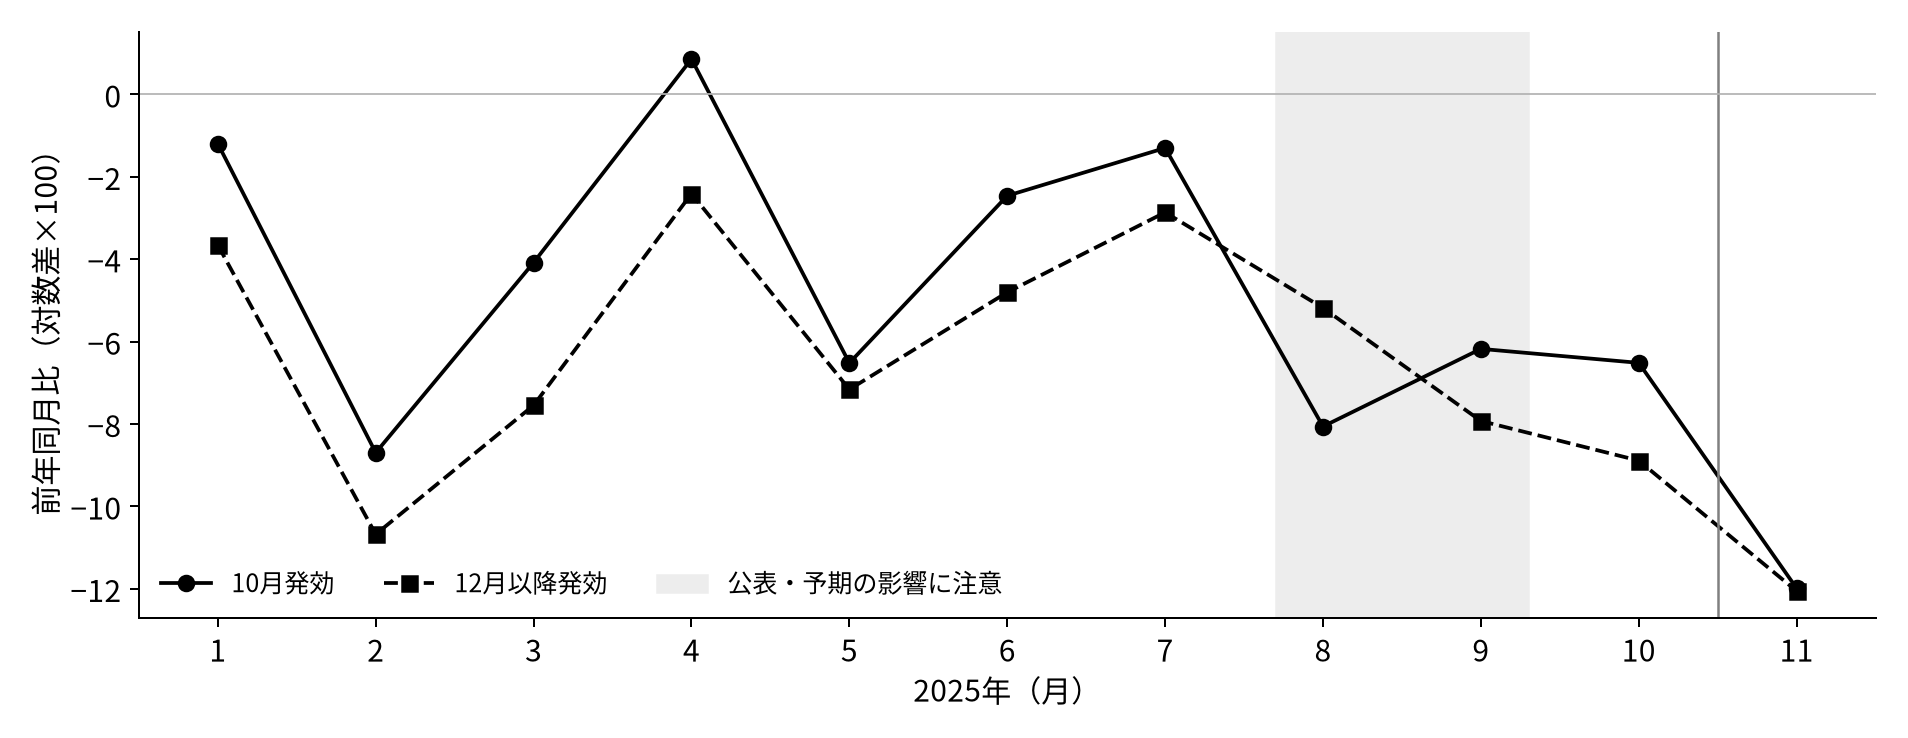

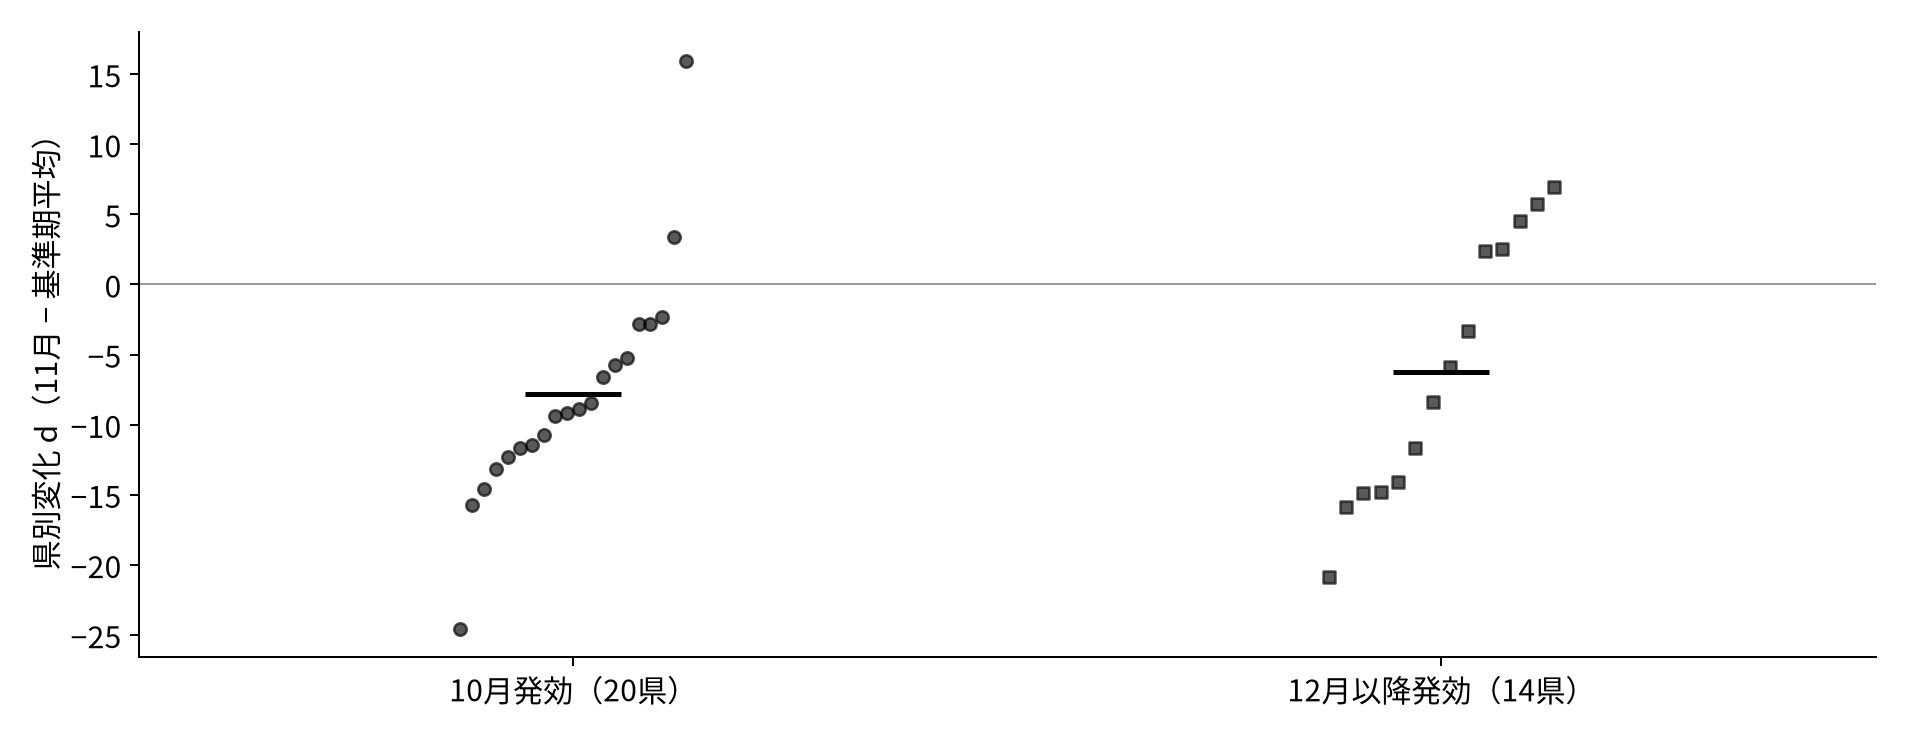

,pref,group,pre_yoy,nov_yoy,d
22,兵庫県,10月発効,-6.1923,-14.6118,-8.4196
0,北海道,10月発効,-4.8547,-18.0328,-13.1782
9,千葉県,10月発効,-2.3940,-18.0911,-15.6972
21,大阪府,10月発効,-3.0657,-17.6261,-14.5604
2,宮城県,10月発効,-6.9265,9.0236,15.9502
13,富山県,10月発効,1.0618,-10.3936,-11.4554
25,山口県,10月発効,-6.5636,-15.9114,-9.3478
18,岐阜県,10月発効,-8.0161,-17.1787,-9.1626
19,愛知県,10月発効,-2.3246,-5.1225,-2.7979
12,新潟県,10月発効,-4.7232,-17.0407,-12.3175


In [5]:
display(Image(filename=str(HERE/'results/trend.png')))
display(Image(filename=str(HERE/'results/county_changes.png')))
display(result['county'].query("baseline == '2025-01..09'")[['pref','group','pre_yoy','nov_yoy','d']].sort_values(['group','pref']).round(4))


## 5. 基準期間の感度
主比較は1〜9月。公表後の予期の可能性を考え1〜7月を追加するが、この期間が完全に予期なしであるとは保証しない。4〜9月は前回の記述統計表に対応する補足。群・比較月は変更しない。これらの区間は多重比較調整をしていない。


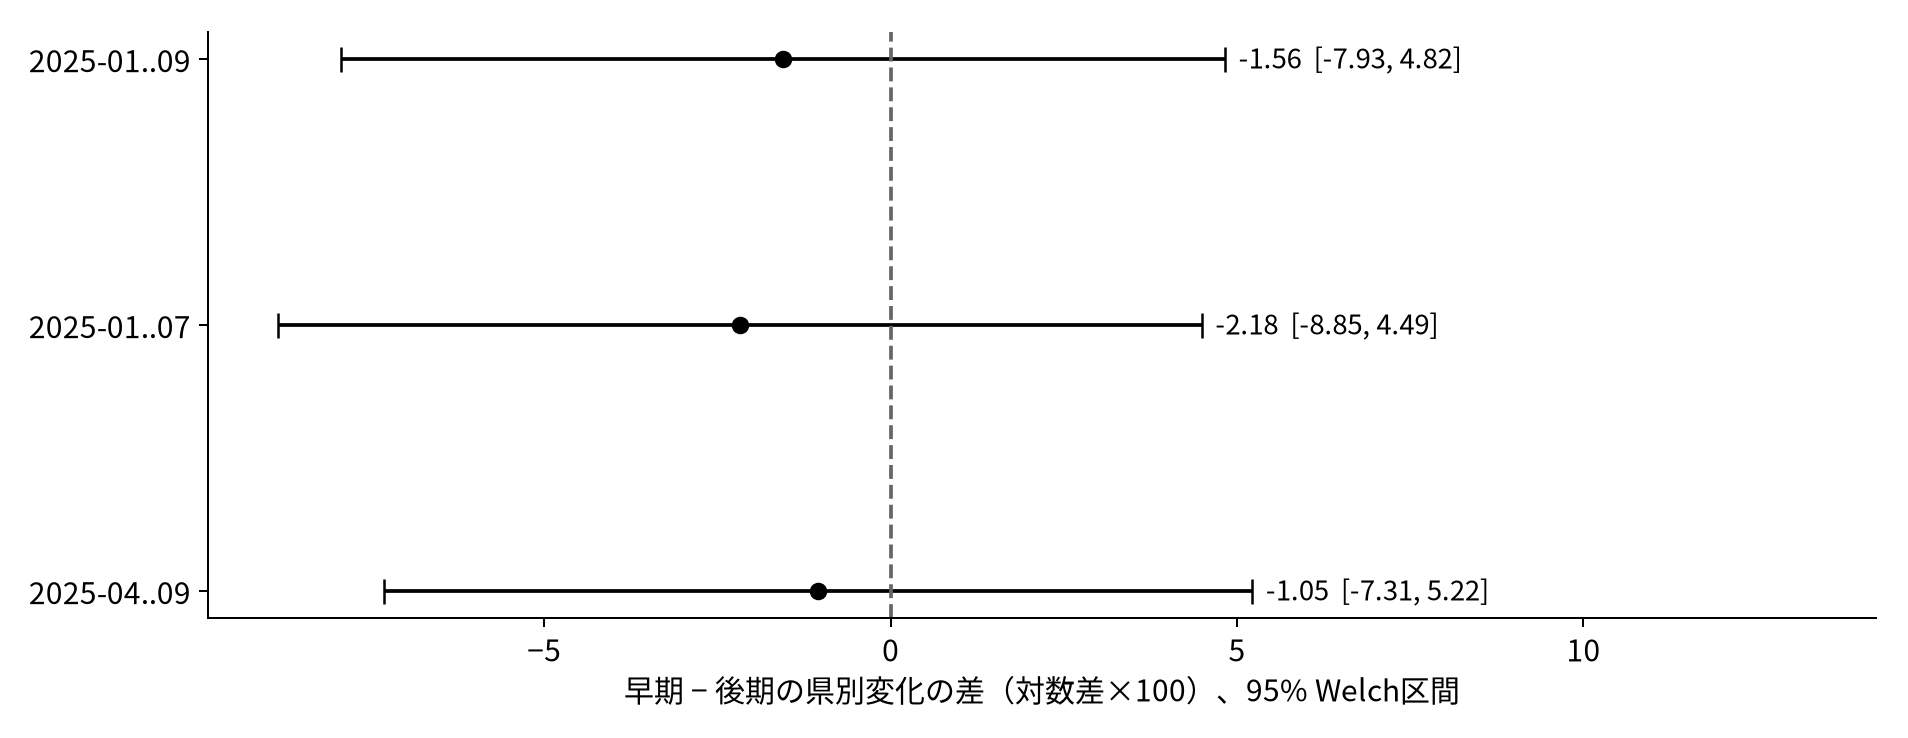

In [6]:
display(Image(filename=str(HERE/'results/sensitivity.png')))

## 6. 独立検算・解釈の限界
同じ県別変化からSciPyの区間を独立に計算し、手計算式を検算する。群ダミーOLSと点推定の一致も確認する。

発効時期はランダムでなく、改定幅も地域特性も異なる。同比は前年の政策影響も差し引く。受理県と就業県は同じとは限らず、民間求人媒体を含まない。県別独立性などの仮定に依存する区間であり、ランダム割付による因果区間ではない。理論の数値検算は実証的な機序の証明ではない。


In [7]:
from scipy import stats
import numpy as np
county=result['county'].query("baseline == '2025-01..09'")
a=county.loc[county.group.eq(analysis.EARLY),'d'].to_numpy()
b=county.loc[county.group.eq(analysis.LATE),'d'].to_numpy()
check=stats.ttest_ind(a,b,equal_var=False)
ci=check.confidence_interval(.95)
assert np.allclose([ci.low,ci.high],[r.ci_low,r.ci_high])
assert np.isclose(check.pvalue,r.p_two_sided)
assert np.isclose(r.delta,r.ols_delta)
assert result['validation']['all_checks_passed']
print('PASS: SciPy confidence interval, two-sided p, OLS point estimate, data and model checks')


PASS: SciPy confidence interval, two-sided p, OLS point estimate, data and model checks


## 参考文献と保存ファイル
OpenStax (2022), §14.1、Ohta and Komae (2022), 本文pp.2, 6–8, 12、Kazekami and Abe (2025), §II–III、Kanayama et al. (2026), arXiv v3, §4・5.2。版と確認した箇所・URLは `sources.md` を参照。

結果は `results/estimates.csv`、全県の中間値は `results/county_changes.csv`、パネルは `results/panel.csv`、データ・数式の検証は `results/verification.json`。再現方法とTODO対応は中国語の `README.md` に記載。
